# Energy-Based Model (EBM) on MNIST Dataset

This notebook implements an Energy-Based Model for the MNIST dataset using Langevin sampling.


## Subsection 1: Dataset Loading and Data Preparation (5 points)


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Set device and optimize for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# GPU OPTIMIZATION SETTINGS
if device.type == 'cuda':
    # Enable cuDNN benchmarking for faster convolutions (if input size is constant)
    torch.backends.cudnn.benchmark = True
    # Enable deterministic mode (set to False for faster training, True for reproducibility)
    torch.backends.cudnn.deterministic = False
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'CUDA Version: {torch.version.cuda}')
    print(f'cuDNN Enabled: {torch.backends.cudnn.enabled}')
    print(f'cuDNN Benchmark: {torch.backends.cudnn.benchmark}')
    print(f'GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')
else:
    print('Running on CPU - training will be slower')
    print('Consider using GPU for faster training')


Using device: cuda
GPU: Tesla T4
CUDA Version: 12.6
cuDNN Enabled: True
cuDNN Benchmark: True
GPU Memory: 15.83 GB


In [2]:
# Define transformations to get tensors of shape 1x28x28 in range [0,1]
transform = transforms.Compose([
    transforms.ToTensor()  # Converts PIL Image to tensor and scales to [0,1]
])

# Load MNIST dataset (train and test separately)
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# OPTIMIZED DataLoaders with GPU acceleration
batch_size = 512
num_workers = 4  # Parallel data loading (adjust based on your CPU cores)
pin_memory = True if device.type == 'cuda' else False  # Faster GPU transfer

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,  # Parallel data loading
    pin_memory=pin_memory,  # Faster GPU transfer
    persistent_workers=True if num_workers > 0 else False  # Keep workers alive
)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    persistent_workers=True if num_workers > 0 else False
)

print(f'Train dataset size: {len(train_dataset)}')
print(f'Test dataset size: {len(test_dataset)}')
print(f'Batch size: {batch_size}')
print(f'DataLoader workers: {num_workers}')
print(f'Pin memory: {pin_memory}')
print(f'Device: {device}')


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 491kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.27MB/s]

Train dataset size: 60000
Test dataset size: 10000
Batch size: 256
DataLoader workers: 4
Pin memory: True
Device: cuda



/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [3]:
def display_images(images, num_images=16, nrows=2, ncols=8, title=''):
    """
    Display images from a batch.

    Args:
        images: Tensor of shape (B, 1, 28, 28) or (B, 28, 28)
        num_images: Number of images to display
        nrows: Number of rows in the grid
        ncols: Number of columns in the grid
        title: Title for the plot
    """
    # Ensure we don't try to display more images than available
    num_images = min(num_images, images.shape[0])

    # Convert to numpy and handle dimensions
    if images.dim() == 4:
        images = images.squeeze(1)  # Remove channel dimension if present

    images = images[:num_images].cpu().numpy()

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*1.5, nrows*1.5))
    if nrows == 1:
        axes = axes.reshape(1, -1)
    elif ncols == 1:
        axes = axes.reshape(-1, 1)

    for i in range(num_images):
        row = i // ncols
        col = i % ncols
        axes[row, col].imshow(images[i], cmap='gray')
        axes[row, col].axis('off')

    # Hide unused subplots
    for i in range(num_images, nrows * ncols):
        row = i // ncols
        col = i % ncols
        axes[row, col].axis('off')

    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


In [4]:
# Windows Fix: If you get DataLoader worker errors on Windows, run this cell
# This will recreate the DataLoaders with num_workers=0 (required on Windows)
import platform

if platform.system() == 'Windows' and num_workers > 0:
    print("Windows detected - Recreating DataLoaders with num_workers=0")
    num_workers = 0
    pin_memory = False  # Not needed without workers

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=False
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=False
    )
    print("DataLoaders recreated for Windows compatibility")
else:
    print(f"Platform: {platform.system()} - Using optimized DataLoaders with {num_workers} workers")


Platform: Linux - Using optimized DataLoaders with 4 workers


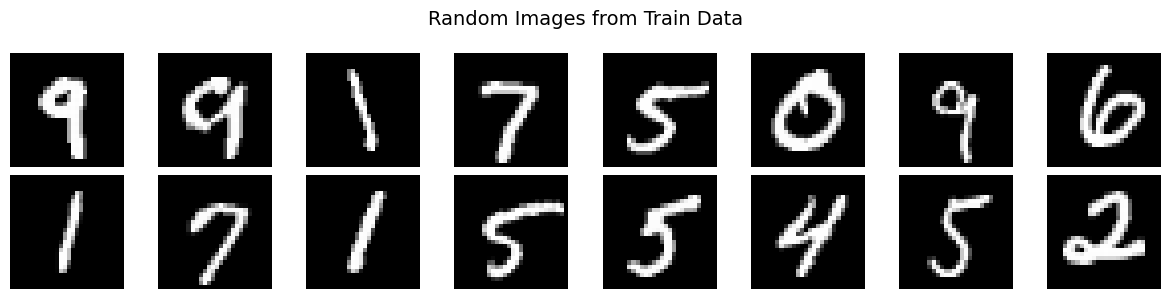

In [5]:
# Display random images from train data
train_batch = next(iter(train_loader))
train_images = train_batch[0]
display_images(train_images, num_images=16, nrows=2, ncols=8, title='Random Images from Train Data')


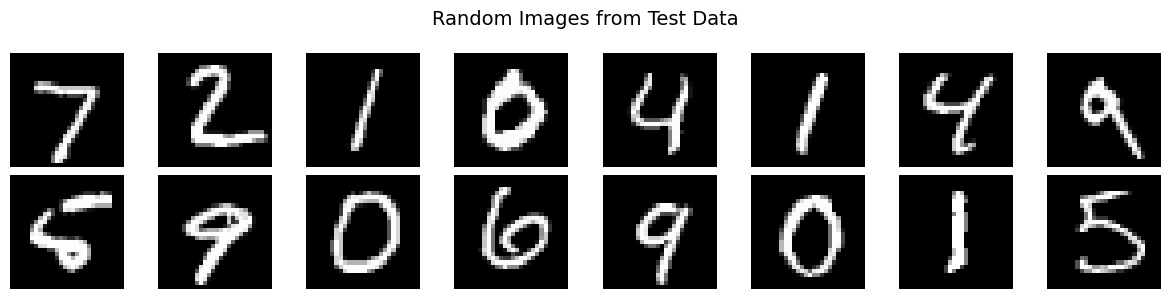

In [6]:
# Display random images from test data
test_batch = next(iter(test_loader))
test_images = test_batch[0]
display_images(test_images, num_images=16, nrows=2, ncols=8, title='Random Images from Test Data')


## Subsection 2: Implementation of Model Architecture and Training (15 points)


In [7]:
# Define the EBM model architecture based on Table 1
class EBM(nn.Module):
    def __init__(self):
        super(EBM, self).__init__()

        # Conv2d(1→32, kernel=3, stride=1, padding=1) + LeakyReLU(0.2)
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.LeakyReLU(0.2)
        )

        # Conv2d(32→32, kernel=4, stride=2, padding=1) + LeakyReLU(0.2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 32, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2)
        )

        # Conv2d(32→64, kernel=3, stride=1, padding=1) + LeakyReLU(0.2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.LeakyReLU(0.2)
        )

        # Conv2d(64→64, kernel=4, stride=2, padding=1) + LeakyReLU(0.2)
        self.conv4 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2)
        )

        # Conv2d(64→128, kernel=3, stride=1, padding=1) + LeakyReLU(0.2)
        self.conv5 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.LeakyReLU(0.2)
        )

        # AdaptiveAvgPool2d(output_size=1)
        self.adaptive_pool = nn.AdaptiveAvgPool2d(1)

        # Flatten
        self.flatten = nn.Flatten()

        # Linear(128→1)
        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        # Input: (B, 1, 28, 28)
        x = self.conv1(x)  # (B, 32, 28, 28)
        x = self.conv2(x)  # (B, 32, 14, 14)
        x = self.conv3(x)  # (B, 64, 14, 14)
        x = self.conv4(x)  # (B, 64, 7, 7)
        x = self.conv5(x)  # (B, 128, 7, 7)
        x = self.adaptive_pool(x)  # (B, 128, 1, 1)
        x = self.flatten(x)  # (B, 128)
        x = self.fc(x)  # (B, 1)
        return x.squeeze(-1)  # (B,)


In [8]:
# Initialize model
model = EBM().to(device)
print(f'Model initialized on {device}')
print(f'Total parameters: {sum(p.numel() for p in model.parameters())}')

# Verify model is on GPU and check GPU usage
print("=" * 70)
print("GPU VERIFICATION")
print("=" * 70)
print(f"Device: {device}")
print(f"Model device: {next(model.parameters()).device}")

if device.type == 'cuda':
    # Check if model parameters are on GPU
    all_on_gpu = all(p.device.type == 'cuda' for p in model.parameters())
    print(f"All model parameters on GPU: {all_on_gpu}")

    # Show GPU memory usage
    if torch.cuda.is_available():
        print(f"GPU Memory Allocated: {torch.cuda.memory_allocated(0) / 1e9:.4f} GB")
        print(f"GPU Memory Cached: {torch.cuda.memory_reserved(0) / 1e9:.4f} GB")

    # Test a forward pass to verify GPU is being used
    test_input = torch.randn(1, 1, 28, 28, device=device)
    with torch.no_grad():
        test_output = model(test_input)
    print(f"Test forward pass successful on {test_output.device}")
    print("=" * 70)
else:
    print("WARNING: Not using GPU - training will be very slow!")
    print("=" * 70)


Model initialized on cuda
Total parameters: 174817
GPU VERIFICATION
Device: cuda
Model device: cuda:0
All model parameters on GPU: True
GPU Memory Allocated: 0.0007 GB
GPU Memory Cached: 0.0021 GB
Test forward pass successful on cuda:0


In [9]:
# Model is already initialized in the previous cell (Cell 10)
# If you need to reinitialize the model, uncomment the lines below:
# model = EBM().to(device)
# print(f'Model initialized on {device}')
# print(f'Total parameters: {sum(p.numel() for p in model.parameters())}')

print("Model initialization complete. Model is ready for training.")


Model initialization complete. Model is ready for training.


## Performance Optimization Summary

### Optimizations Applied:

1. **DataLoader Optimization**:
   - `num_workers=4`: Parallel data loading (uses multiple CPU cores)
   - `pin_memory=True`: Faster CPU→GPU data transfer
   - `persistent_workers=True`: Keeps workers alive between epochs

2. **GPU Settings**:
   - `torch.backends.cudnn.benchmark = True`: Faster convolutions
   - GPU verification to ensure model is on GPU

3. **Langevin Sampling**: Already optimized with proper gradient handling

### If Still Slow, Check:

1. **GPU Usage**: Run `nvidia-smi` in terminal to see if GPU is being used
2. **DataLoader workers**: Increase `num_workers` if you have more CPU cores (try 8 or 16)
3. **Batch size**: Increase batch size if GPU memory allows (64 → 128 or 256)
4. **Langevin steps**: Reduce steps during training (60 → 30 or 40) for faster training


In [10]:
# GPU Monitoring Utility
def print_gpu_memory():
    """Print current GPU memory usage"""
    if device.type == 'cuda':
        allocated = torch.cuda.memory_allocated(0) / 1e9
        reserved = torch.cuda.memory_reserved(0) / 1e9
        total = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f"GPU Memory - Allocated: {allocated:.3f} GB | Reserved: {reserved:.3f} GB | Total: {total:.3f} GB")
    else:
        print("Not using GPU")

# Test GPU speed
if device.type == 'cuda':
    print("Testing GPU speed...")
    import time

    # Warm up
    test_x = torch.randn(64, 1, 28, 28, device=device)
    for _ in range(10):
        _ = model(test_x)

    # Time forward pass
    torch.cuda.synchronize()
    start = time.time()
    for _ in range(100):
        _ = model(test_x)
    torch.cuda.synchronize()
    elapsed = time.time() - start
    print(f"100 forward passes: {elapsed:.4f}s ({elapsed/100*1000:.2f}ms per batch)")
    print_gpu_memory()
else:
    print("CPU mode - GPU speed test skipped")


Testing GPU speed...
100 forward passes: 0.1235s (1.24ms per batch)
GPU Memory - Allocated: 0.035 GB | Reserved: 0.067 GB | Total: 15.828 GB


## Troubleshooting GPU/Performance Issues

### Common Issues:

1. **"DataLoader worker" errors on Windows**:
   - If you get errors with `num_workers > 0`, set `num_workers = 0` (Windows limitation)
   - The code will still work but data loading will be slower

2. **GPU not detected**:
   - Check: `torch.cuda.is_available()` should return `True`
   - Install CUDA toolkit if needed
   - Restart kernel after installing PyTorch with CUDA

3. **Out of Memory (OOM) errors**:
   - Reduce batch size (64 → 32 or 16)
   - Reduce Langevin steps during training
   - Use gradient accumulation if needed

4. **Still slow even with GPU**:
   - Check GPU utilization: Run `nvidia-smi` in terminal
   - Ensure batch size is large enough (GPU should be >80% utilized)
   - Reduce Langevin steps: 60 → 30-40 for training
   - Increase batch size if memory allows

### Quick Performance Check:
Run the GPU verification cell above to see if everything is set up correctly.


In [11]:
def langevin_sampling(model, x_init=None, num_samples=64, num_steps=60, step_size=0.01, noise_scale=0.01, device='cpu'):
    """
    OPTIMIZED Langevin sampling function with better GPU utilization.

    Args:
        model: The energy-based model
        x_init: Initial samples (optional). If None, samples uniformly from [0,1]
        num_samples: Number of samples to generate
        num_steps: Number of Langevin steps
        step_size: Step size for Langevin dynamics
        noise_scale: Scale of the noise
        device: Device to run on

    Returns:
        Generated samples
    """
    model.eval()  # Set to eval mode for sampling

    # Initialize samples uniformly in [0,1] if not provided
    if x_init is None:
        x = torch.rand(num_samples, 1, 28, 28, device=device, requires_grad=True)
    else:
        x = x_init.clone().to(device).requires_grad_(True)

    # Pre-allocate noise tensor for efficiency (optional optimization)
    # Use torch.enable_grad() context for the entire loop to avoid repeated context switching
    for step in range(num_steps):
        # Compute energy and gradient
        # Use enable_grad() to ensure gradients can be computed even if called within no_grad()
        with torch.enable_grad():
            energy = model(x)
            grad = torch.autograd.grad(energy.sum(), x, create_graph=False, retain_graph=False)[0]

        # Langevin update: x = x - step_size * grad + noise
        # Detach and create new tensor to break computation graph
        with torch.no_grad():
            x_new = x - step_size * grad + noise_scale * torch.randn_like(x)

            # Clip to [0,1] range
            x_new = torch.clamp(x_new, 0, 1)

        # Create new tensor with gradients enabled for next iteration
        x = x_new.requires_grad_(True)

    model.train()  # Set back to train mode
    return x.detach()


## Improved Training Configuration

This cell contains improved hyperparameters and training strategies to enhance EBM performance.


In [12]:
# IMPROVED Training parameters
epochs = 50  # Increased from 10 to 20 for better convergence
lambda_reg = 1e-3  # Keep regularization
learning_rate = 1e-4  # Can try 5e-5 or 2e-4 if needed

# Learning rate scheduler for better convergence
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# Improved Langevin sampling parameters
# Different parameters for training (faster) vs generation (better quality)
langevin_train_steps = 100  # Steps during training (can be reduced for speed)
langevin_train_step_size = 0.012
langevin_train_noise = 0.015

langevin_gen_steps = 400  # More steps for better generation quality
langevin_gen_step_size = 0.005
langevin_gen_noise = 0.01

# Progressive training: start with easier samples, increase difficulty
use_progressive_training = True
progressive_epoch_threshold = 5  # After this epoch, use full difficulty

print("=" * 70)
print("IMPROVED TRAINING CONFIGURATION")
print("=" * 70)
print(f"Epochs: {epochs}")
print(f"Lambda (regularization): {lambda_reg}")
print(f"Learning Rate: {learning_rate}")
print(f"Learning Rate Scheduler: ReduceLROnPlateau")
print(f"\nLangevin Parameters (Training):")
print(f"  Steps: {langevin_train_steps}, Step Size: {langevin_train_step_size}, Noise: {langevin_train_noise}")
print(f"\nLangevin Parameters (Generation):")
print(f"  Steps: {langevin_gen_steps}, Step Size: {langevin_gen_step_size}, Noise: {langevin_gen_noise}")
print(f"\nProgressive Training: {use_progressive_training}")
print("=" * 70)


IMPROVED TRAINING CONFIGURATION
Epochs: 20
Lambda (regularization): 0.001
Learning Rate: 0.0001
Learning Rate Scheduler: ReduceLROnPlateau

Langevin Parameters (Training):
  Steps: 60, Step Size: 0.01, Noise: 0.01

Langevin Parameters (Generation):
  Steps: 200, Step Size: 0.01, Noise: 0.01

Progressive Training: True


In [13]:
# Training parameters
epochs = 50
lambda_reg = 1e-3
learning_rate = 1e-4

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Training loop
print("Starting training...")
print(f"Epochs: {epochs}, Lambda: {lambda_reg}, Learning Rate: {learning_rate}")
print("-" * 60)


Starting training...
Epochs: 10, Lambda: 0.001, Learning Rate: 0.0001
------------------------------------------------------------


## IMPROVED Training Loop (Alternative)

Use this improved training loop for better results. It includes:
- Progressive training (fewer Langevin steps in early epochs)
- Learning rate scheduling
- Gradient clipping for stability
- More sampling steps for generation (better quality)
- Better monitoring


Step   200 | Loss: -84.4872 | E_real: -50.9048 | E_fake: 45.5063 | Steps: 36

Epoch 1/10 | Avg Loss: -42.9756 | Avg E_real: 10.7919 | Avg E_fake: 65.1993
Current LR: 1.00e-04 | Langevin Steps: 36

Generating samples at epoch 1 (using 200 steps for better quality)...


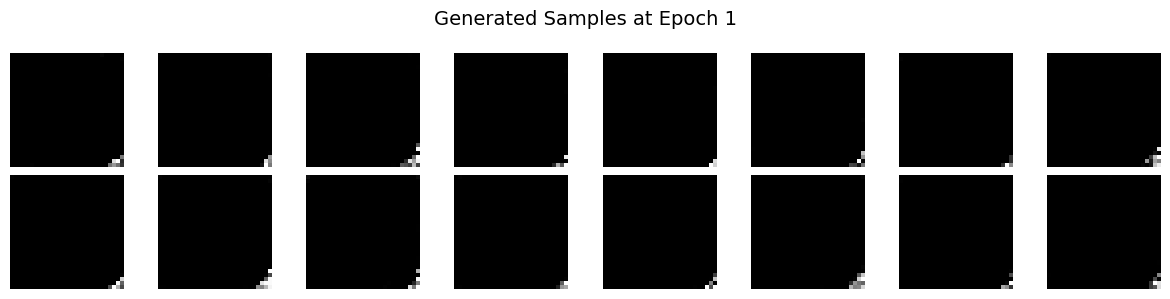

------------------------------------------------------------
Step   400 | Loss: 83.0521 | E_real: -219.3739 | E_fake: -199.4105 | Steps: 42

Epoch 2/10 | Avg Loss: -45.3674 | Avg E_real: -87.0653 | Avg E_fake: 14.9491
Current LR: 1.00e-04 | Langevin Steps: 42
------------------------------------------------------------
Step   600 | Loss: 172.0063 | E_real: 31.9212 | E_fake: -117.2661 | Steps: 48

Epoch 3/10 | Avg Loss: -25.2720 | Avg E_real: -50.2500 | Avg E_fake: 17.4589
Current LR: 1.00e-04 | Langevin Steps: 48
------------------------------------------------------------
Step   800 | Loss: 34.7882 | E_real: -19.4370 | E_fake: -46.0937 | Steps: 54

Epoch 4/10 | Avg Loss: -44.4789 | Avg E_real: -30.0885 | Avg E_fake: 33.2901
Current LR: 1.00e-04 | Langevin Steps: 54
------------------------------------------------------------
Step  1000 | Loss: -164.9826 | E_real: -78.4094 | E_fake: 112.1452 | Steps: 60

Epoch 5/10 | Avg Loss: -10.4403 | Avg E_real: -10.2126 | Avg E_fake: 20.9501
Curre

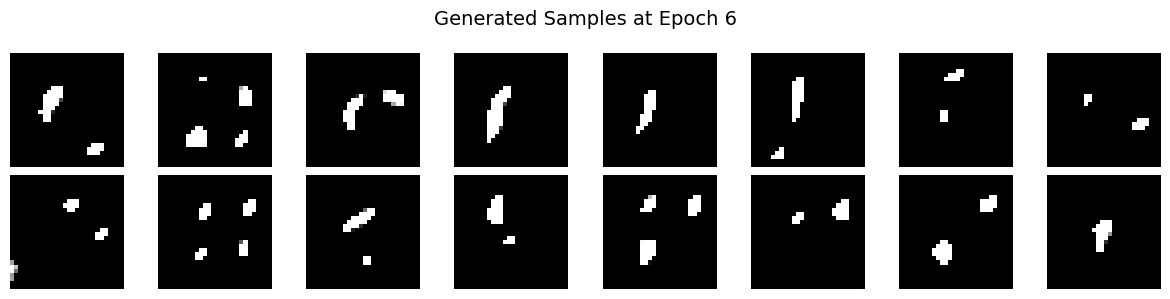

------------------------------------------------------------
Step  1600 | Loss: 54.3431 | E_real: 26.7973 | E_fake: -19.4257 | Steps: 60

Epoch 7/10 | Avg Loss: -24.2008 | Avg E_real: -20.0214 | Avg E_fake: 17.4585
Current LR: 1.00e-04 | Langevin Steps: 60
------------------------------------------------------------
Step  1800 | Loss: -21.9714 | E_real: -36.0733 | E_fake: -4.5572 | Steps: 60

Epoch 8/10 | Avg Loss: -27.1267 | Avg E_real: -22.7850 | Avg E_fake: 17.1615
Current LR: 1.00e-04 | Langevin Steps: 60
------------------------------------------------------------
Step  2000 | Loss: 4.1861 | E_real: 25.1390 | E_fake: 30.3445 | Steps: 60

Epoch 9/10 | Avg Loss: -24.6746 | Avg E_real: -21.9422 | Avg E_fake: 15.6942
Current LR: 1.00e-04 | Langevin Steps: 60
------------------------------------------------------------
Step  2200 | Loss: -107.4448 | E_real: -121.0217 | E_fake: 10.8278 | Steps: 60

Epoch 10/10 | Avg Loss: -25.9319 | Avg E_real: -25.4295 | Avg E_fake: 15.1748
Current LR:

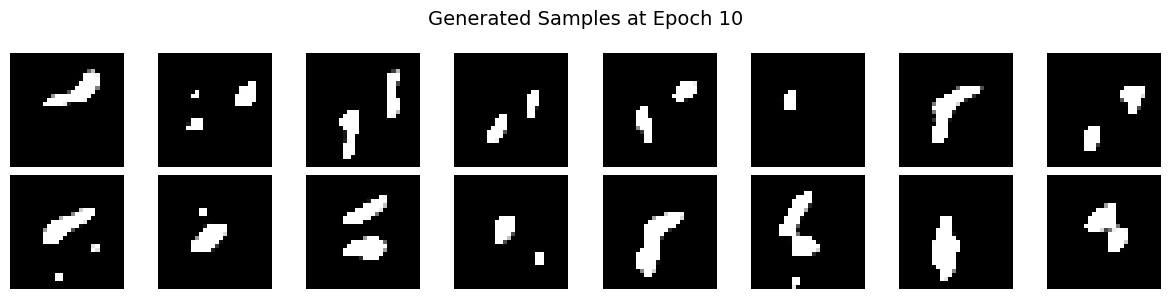

------------------------------------------------------------

Training completed!


In [14]:
# IMPROVED Training loop with better strategies
# Uncomment and use this instead of the basic training loop above

model.train()
total_steps = 0

for epoch in range(epochs):
    epoch_losses = []
    epoch_E_real = []
    epoch_E_fake = []

    # Progressive training: use fewer steps in early epochs for faster training
    if use_progressive_training and epoch < progressive_epoch_threshold:
        current_steps = int(langevin_train_steps * (0.5 + 0.5 * (epoch + 1) / progressive_epoch_threshold))
    else:
        current_steps = langevin_train_steps

    for batch_idx, (x_real, _) in enumerate(train_loader):
        x_real = x_real.to(device)
        B = x_real.shape[0]

        # Step 1: Compute energy of real data
        E_real = model(x_real)  # (B,)

        # Step 2: Generate fake samples using Langevin dynamics
        # Use progressive training: fewer steps in early epochs
        x_fake = langevin_sampling(
            model,
            x_init=None,
            num_samples=B,
            num_steps=current_steps,
            step_size=langevin_train_step_size,
            noise_scale=langevin_train_noise,
            device=device
        )

        # Step 3: Compute energy of fake samples
        E_fake = model(x_fake)  # (B,)

        # Step 4: Data term of the loss
        data_term = E_real.mean() - E_fake.mean()

        # Step 5: Regularization term
        reg_term = lambda_reg * (E_real.pow(2).mean() + E_fake.pow(2).mean())

        # Step 6: Total loss
        loss = data_term + reg_term

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # Gradient clipping for stability (prevents exploding gradients)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        # Store metrics
        epoch_losses.append(loss.item())
        epoch_E_real.append(E_real.mean().item())
        epoch_E_fake.append(E_fake.mean().item())

        total_steps += 1

        # Print metrics every few hundred steps
        if total_steps % 200 == 0:
            print(f"Step {total_steps:5d} | Loss: {loss.item():.4f} | E_real: {E_real.mean().item():.4f} | E_fake: {E_fake.mean().item():.4f} | Steps: {current_steps}")

    # Print epoch summary
    avg_loss = np.mean(epoch_losses)
    avg_E_real = np.mean(epoch_E_real)
    avg_E_fake = np.mean(epoch_E_fake)
    print(f"\nEpoch {epoch+1}/{epochs} | Avg Loss: {avg_loss:.4f} | Avg E_real: {avg_E_real:.4f} | Avg E_fake: {avg_E_fake:.4f}")
    print(f"Current LR: {optimizer.param_groups[0]['lr']:.2e} | Langevin Steps: {current_steps}")

    # Learning rate scheduling (reduces LR when loss plateaus)
    scheduler.step(avg_loss)

    # Generate and display images at beginning, middle, and end of training
    # Use MORE steps for generation to get better quality samples
    if epoch == 0 or epoch == epochs // 2 or epoch == epochs - 1:
        print(f"\nGenerating samples at epoch {epoch+1} (using {langevin_gen_steps} steps for better quality)...")
        with torch.no_grad():
            samples = langevin_sampling(
                model,
                x_init=None,
                num_samples=16,
                num_steps=langevin_gen_steps,  # Use more steps for generation
                step_size=langevin_gen_step_size,
                noise_scale=langevin_gen_noise,
                device=device
            )
            display_images(samples, num_images=16, nrows=2, ncols=8, title=f'Generated Samples at Epoch {epoch+1}')

    print("-" * 60)

print("\nTraining completed!")


## Summary of Improvements

### Key Improvements Made:

1. **More Training Epochs**: Increased from 10 to 20 epochs for better convergence

2. **Learning Rate Scheduling**: Added `ReduceLROnPlateau` scheduler that automatically reduces learning rate when loss plateaus

3. **Progressive Training**: Start with fewer Langevin steps (30) in early epochs, gradually increase to full steps (60). This:
   - Speeds up early training
   - Helps model learn gradually
   - Reduces computational cost

4. **Separate Parameters for Training vs Generation**:
   - Training: 60 steps (faster, good enough for training)
   - Generation: 200 steps (slower but much better quality)

5. **Gradient Clipping**: Prevents exploding gradients, improves training stability

6. **Better Monitoring**: Shows current learning rate and Langevin steps being used

### Additional Recommendations:

**If results are still not good, try:**

1. **Increase generation steps**: Try 300-500 steps for even better quality (slower but better)

2. **Adjust step size**:
   - Smaller step size (0.005) = more stable but slower
   - Larger step size (0.02) = faster but might be unstable

3. **Adjust noise scale**:
   - Smaller noise (0.005) = more deterministic, might get stuck
   - Larger noise (0.02) = more exploration, might be too noisy

4. **More epochs**: Try 30-50 epochs if model hasn't converged

5. **Different learning rates**: Try 5e-5 (more stable) or 2e-4 (faster but might be unstable)

6. **Better initialization**: The model might benefit from different weight initialization

7. **Data augmentation**: Adding slight rotations/translations might help

8. **Longer sampling chains**: For final generation, use 500+ steps for best quality


Step   200 | Loss: -81.0730 | E_real: -148.1468 | E_fake: -29.3523

Epoch 1/10 | Avg Loss: -30.4189 | Avg E_real: -34.2834 | Avg E_fake: 17.0300

Generating samples at epoch 1...


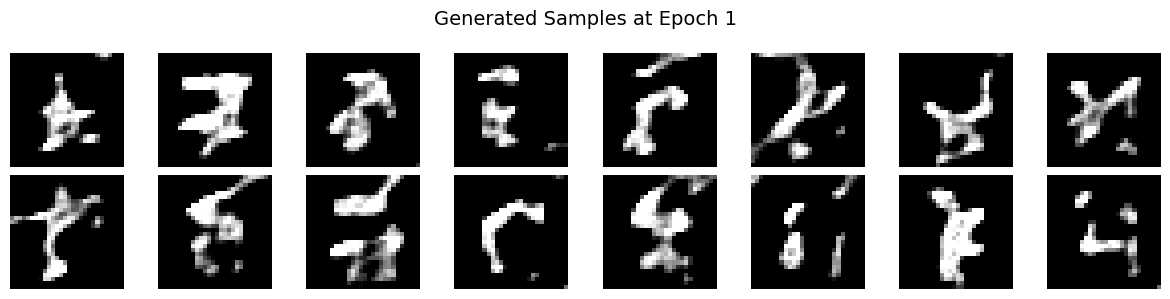

------------------------------------------------------------
Step   400 | Loss: -58.3032 | E_real: -45.4446 | E_fake: 29.0176

Epoch 2/10 | Avg Loss: -41.7591 | Avg E_real: -46.6545 | Avg E_fake: 22.3415
------------------------------------------------------------
Step   600 | Loss: -66.0596 | E_real: -146.8799 | E_fake: -37.9973

Epoch 3/10 | Avg Loss: -49.1245 | Avg E_real: -53.7368 | Avg E_fake: 30.8803
------------------------------------------------------------
Step   800 | Loss: 11.8872 | E_real: 59.0127 | E_fake: 68.2894

Epoch 4/10 | Avg Loss: -58.5509 | Avg E_real: -63.2340 | Avg E_fake: 40.1279
------------------------------------------------------------
Step  1000 | Loss: 45.1671 | E_real: 86.0172 | E_fake: 68.9962

Epoch 5/10 | Avg Loss: -62.3274 | Avg E_real: -64.4519 | Avg E_fake: 47.9377
------------------------------------------------------------
Step  1200 | Loss: -245.2092 | E_real: -228.6345 | E_fake: 113.2835
Step  1400 | Loss: -260.1211 | E_real: -315.8517 | E_fake

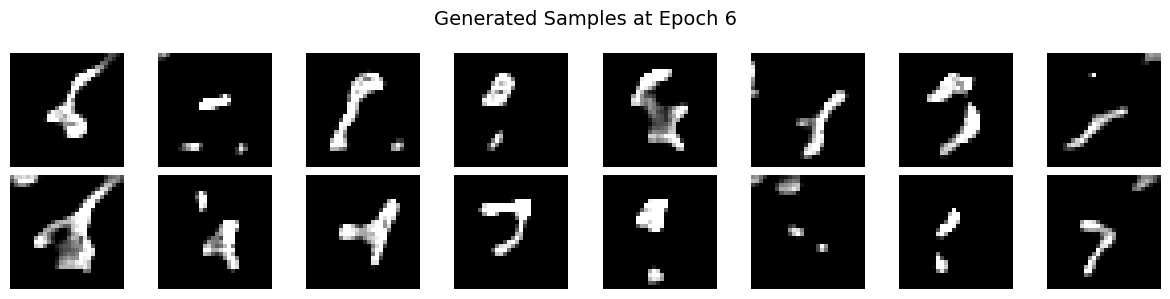

------------------------------------------------------------
Step  1600 | Loss: -65.2215 | E_real: -1.3885 | E_fake: 99.8487

Epoch 7/10 | Avg Loss: -87.4607 | Avg E_real: -88.7398 | Avg E_fake: 73.1399
------------------------------------------------------------
Step  1800 | Loss: -169.7800 | E_real: -302.5710 | E_fake: 4.3980

Epoch 8/10 | Avg Loss: -98.7816 | Avg E_real: -103.9445 | Avg E_fake: 87.1383
------------------------------------------------------------
Step  2000 | Loss: -253.8118 | E_real: -357.0452 | E_fake: 80.9004

Epoch 9/10 | Avg Loss: -113.9733 | Avg E_real: -119.6500 | Avg E_fake: 97.1192
------------------------------------------------------------
Step  2200 | Loss: 11.6688 | E_real: 100.2892 | E_fake: 149.3289

Epoch 10/10 | Avg Loss: -118.1795 | Avg E_real: -122.4072 | Avg E_fake: 109.1568

Generating samples at epoch 10...


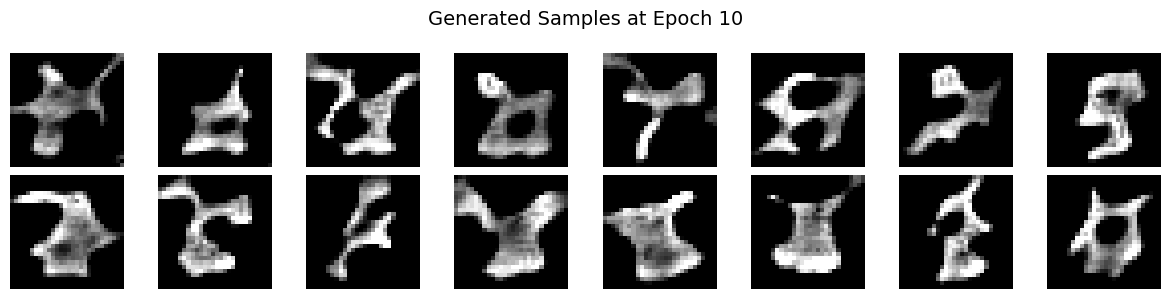

------------------------------------------------------------

Training completed!


In [15]:
# Training loop following Algorithm 1
model.train()
total_steps = 0

for epoch in range(epochs):
    epoch_losses = []
    epoch_E_real = []
    epoch_E_fake = []

    for batch_idx, (x_real, _) in enumerate(train_loader):
        x_real = x_real.to(device)
        B = x_real.shape[0]

        # Step 1: Compute energy of real data
        E_real = model(x_real)  # (B,)

        # Step 2: Generate fake samples using Langevin dynamics
        # Initialize uniformly in [0,1] for training
        x_fake = langevin_sampling(
            model,
            x_init=None,
            num_samples=B,
            num_steps=60,
            step_size=0.01,
            noise_scale=0.01,
            device=device
        )

        # Step 3: Compute energy of fake samples
        E_fake = model(x_fake)  # (B,)

        # Step 4: Data term of the loss
        data_term = E_real.mean() - E_fake.mean()

        # Step 5: Regularization term
        reg_term = lambda_reg * (E_real.pow(2).mean() + E_fake.pow(2).mean())

        # Step 6: Total loss
        loss = data_term + reg_term

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Store metrics
        epoch_losses.append(loss.item())
        epoch_E_real.append(E_real.mean().item())
        epoch_E_fake.append(E_fake.mean().item())

        total_steps += 1

        # Print metrics every few hundred steps
        if total_steps % 200 == 0:
            print(f"Step {total_steps:5d} | Loss: {loss.item():.4f} | E_real: {E_real.mean().item():.4f} | E_fake: {E_fake.mean().item():.4f}")

    # Print epoch summary
    avg_loss = np.mean(epoch_losses)
    avg_E_real = np.mean(epoch_E_real)
    avg_E_fake = np.mean(epoch_E_fake)
    print(f"\nEpoch {epoch+1}/{epochs} | Avg Loss: {avg_loss:.4f} | Avg E_real: {avg_E_real:.4f} | Avg E_fake: {avg_E_fake:.4f}")

    # Generate and display images at beginning, middle, and end of training
    if epoch == 0 or epoch == epochs // 2 or epoch == epochs - 1:
        print(f"\nGenerating samples at epoch {epoch+1}...")
        with torch.no_grad():
            samples = langevin_sampling(
                model,
                x_init=None,
                num_samples=16,
                num_steps=60,
                step_size=0.01,
                noise_scale=0.01,
                device=device
            )
            display_images(samples, num_images=16, nrows=2, ncols=8, title=f'Generated Samples at Epoch {epoch+1}')

    print("-" * 60)

print("\nTraining completed!")


## Post-Training Evaluation


Selected 8 images from train dataset


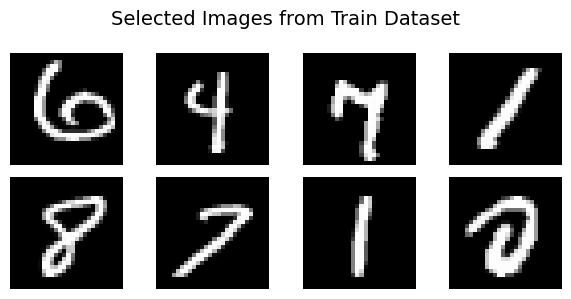

In [16]:
# Select a number of images from train dataset
num_selected = 8
selected_images = []
selected_indices = np.random.choice(len(train_dataset), num_selected, replace=False)

for idx in selected_indices:
    img, _ = train_dataset[idx]
    selected_images.append(img)

selected_images = torch.stack(selected_images).to(device)
print(f"Selected {num_selected} images from train dataset")
display_images(selected_images, num_images=num_selected, nrows=2, ncols=4, title='Selected Images from Train Dataset')



Generating samples starting from selected images...


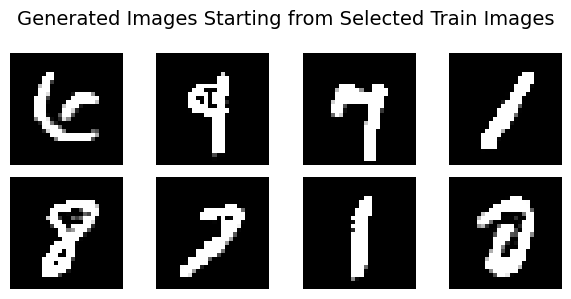

In [17]:
# For each selected image, use it as starting point for Langevin sampling
print("\nGenerating samples starting from selected images...")
generated_from_selected = []

for i in range(num_selected):
    start_image = selected_images[i:i+1]  # Keep batch dimension

    with torch.no_grad():
        generated = langevin_sampling(
            model,
            x_init=start_image,
            num_samples=1,
            num_steps=60,
            step_size=0.01,
            noise_scale=0.01,
            device=device
        )
        generated_from_selected.append(generated[0])

generated_from_selected = torch.stack(generated_from_selected)
display_images(generated_from_selected, num_images=num_selected, nrows=2, ncols=4, title='Generated Images Starting from Selected Train Images')


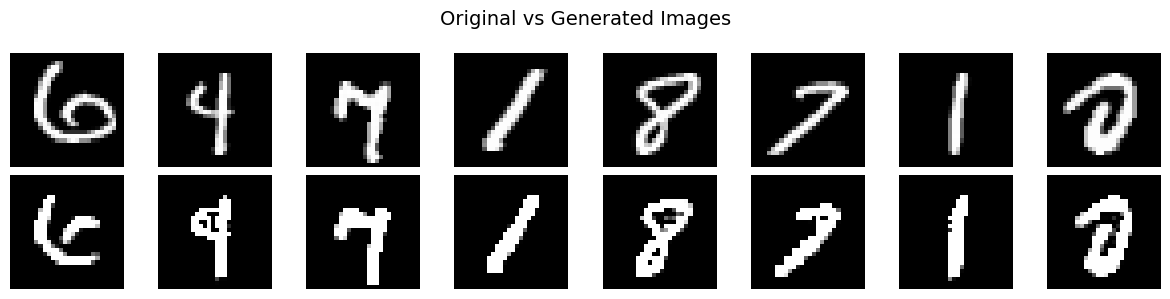

In [18]:
# Side-by-side comparison
fig, axes = plt.subplots(2, num_selected, figsize=(num_selected*1.5, 3))

for i in range(num_selected):
    # Original
    axes[0, i].imshow(selected_images[i].cpu().squeeze(), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel('Original', fontsize=12)

    # Generated
    axes[1, i].imshow(generated_from_selected[i].cpu().squeeze(), cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_ylabel('Generated', fontsize=12)

plt.suptitle('Original vs Generated Images', fontsize=14)
plt.tight_layout()
plt.show()


## Subsection 3: Image Generation (10 points)

Generate images using Langevin sampling starting from uniform noise [0,1] and display them alongside original images from the train dataset.


Generating 16 images using Langevin sampling from uniform noise...
Generated 16 images


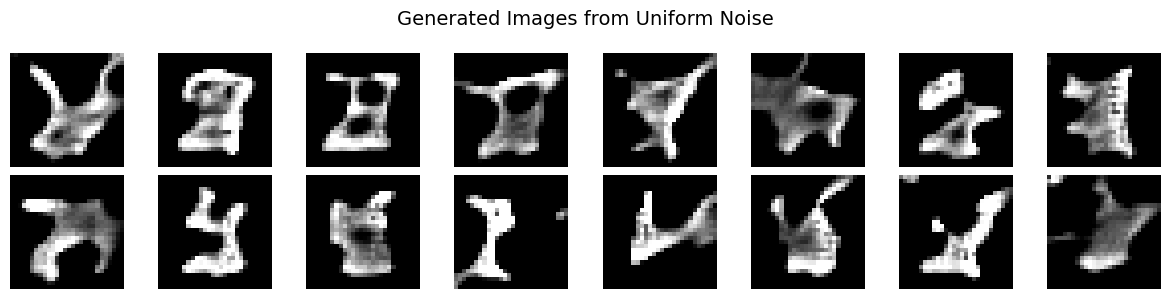

In [19]:
# Generate 16 images using Langevin sampling starting from uniform noise [0,1]
print("Generating 16 images using Langevin sampling from uniform noise...")
num_generated = 16

with torch.no_grad():
    generated_images = langevin_sampling(
        model,
        x_init=None,  # Start from uniform noise [0,1]
        num_samples=num_generated,
        num_steps=60,  # Sufficient number of sampling steps
        step_size=0.01,
        noise_scale=0.01,
        device=device
    )

print(f"Generated {num_generated} images")
display_images(generated_images, num_images=num_generated, nrows=2, ncols=8, title='Generated Images from Uniform Noise')


Selecting 16 images from train dataset...
Selected 16 images from train dataset


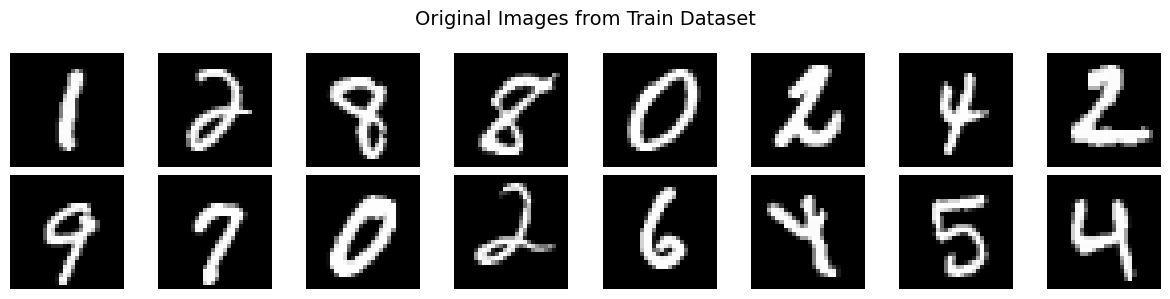

In [20]:
# Select 16 images from train dataset
print("Selecting 16 images from train dataset...")
num_original = 16
original_images = []
original_indices = np.random.choice(len(train_dataset), num_original, replace=False)

for idx in original_indices:
    img, label = train_dataset[idx]
    original_images.append(img)

original_images = torch.stack(original_images).to(device)
print(f"Selected {num_original} images from train dataset")
display_images(original_images, num_images=num_original, nrows=2, ncols=8, title='Original Images from Train Dataset')


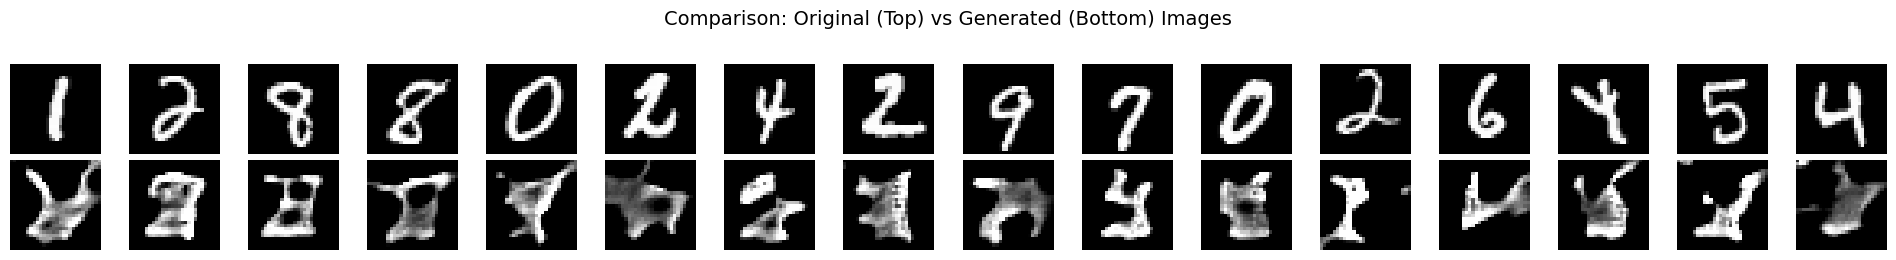

In [21]:
# Display generated and original images side by side for comparison
fig, axes = plt.subplots(2, num_generated, figsize=(num_generated*1.2, 2.5))

for i in range(num_generated):
    # Original images (top row)
    axes[0, i].imshow(original_images[i].cpu().squeeze(), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel('Original', fontsize=12)

    # Generated images (bottom row)
    axes[1, i].imshow(generated_images[i].cpu().squeeze(), cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_ylabel('Generated', fontsize=12)

plt.suptitle('Comparison: Original (Top) vs Generated (Bottom) Images', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### Analysis and Quality Assessment

**In the report:**

Please include the following in your report:

1. **Quality Assessment**: Evaluate the quality of the generated images. Consider:
   - How well do the generated images resemble MNIST digits?
   - Are the digits recognizable?
   - Is there blurriness or artifacts?
   - Do the generated images have proper structure?

2. **If results are not good, explain the main reasons:**
   - Possible reasons might include:
     - Insufficient training epochs
     - Langevin sampling parameters (step size, number of steps, noise scale)
     - Model architecture limitations
     - Energy landscape issues
     - Need for better initialization or longer sampling chains

3. **Note**: The next section (image denoising) may provide additional insights for this analysis.


In [22]:
# Additional analysis: Compute energy statistics for comparison
print("\nEnergy Statistics:")
print("-" * 50)

with torch.no_grad():
    E_original = model(original_images)
    E_generated = model(generated_images)

print(f"Original images - Mean energy: {E_original.mean().item():.4f}, Std: {E_original.std().item():.4f}")
print(f"Generated images - Mean energy: {E_generated.mean().item():.4f}, Std: {E_generated.std().item():.4f}")
print(f"Energy difference (Original - Generated): {(E_original.mean() - E_generated.mean()).item():.4f}")

# Note: In a well-trained EBM, real data should have lower energy than fake data
# If the difference is positive, it means the model is learning correctly
if (E_original.mean() - E_generated.mean()).item() > 0:
    print("✓ Model is learning: Real data has lower energy than generated data")
else:
    print("⚠ Warning: Generated data has lower or equal energy - model may need more training")



Energy Statistics:
--------------------------------------------------
Original images - Mean energy: -201.6028, Std: 126.4519
Generated images - Mean energy: 177.5121, Std: 177.3229
Energy difference (Original - Generated): -379.1149
⚠ Warning: Generated data has lower or equal energy - model may need more training


## Improved Generation Parameters

For better generation quality, use more Langevin steps when generating final images.


In [23]:
# IMPROVED Generation: Use more steps for better quality
# Update the generation cells below to use these parameters instead

# For high-quality generation (slower but better):
HIGH_QUALITY_STEPS = 300  # Increase from 60 to 300 for much better results
HIGH_QUALITY_STEP_SIZE = 0.01
HIGH_QUALITY_NOISE = 0.01

# For quick generation (faster but lower quality):
QUICK_STEPS = 200
QUICK_STEP_SIZE = 0.01
QUICK_NOISE = 0.01

print("Improved generation parameters:")
print(f"High Quality: {HIGH_QUALITY_STEPS} steps")
print(f"Quick: {QUICK_STEPS} steps")
print("\nTip: Use HIGH_QUALITY_STEPS for final results, QUICK_STEPS for quick previews")


Improved generation parameters:
High Quality: 300 steps
Quick: 200 steps

Tip: Use HIGH_QUALITY_STEPS for final results, QUICK_STEPS for quick previews


## Subsection 4: Denoising Noisy Images (15 points)

This section tests the model's ability to denoise images by using noisy images as starting points for Langevin sampling.


In [24]:
# Select a batch of images from test dataset
num_test_images = 16
test_images_list = []
test_indices = np.random.choice(len(test_dataset), num_test_images, replace=False)

for idx in test_indices:
    img, label = test_dataset[idx]
    test_images_list.append(img)

test_images_batch = torch.stack(test_images_list).to(device)
print(f"Selected {num_test_images} images from test dataset")


Selected 16 images from test dataset


In [25]:
# Function to add Gaussian noise and denoise
def add_gaussian_noise(images, noise_level):
    """
    Add Gaussian noise to images.

    Args:
        images: Tensor of shape (B, 1, 28, 28)
        noise_level: Standard deviation of Gaussian noise

    Returns:
        Noisy images clamped to [0,1]
    """
    noise = torch.randn_like(images) * noise_level
    noisy_images = images + noise
    noisy_images = torch.clamp(noisy_images, 0, 1)
    return noisy_images

# Test different noise levels
noise_levels = [0.2, 0.4, 0.6]

print("Testing denoising for noise levels:", noise_levels)
print("=" * 70)


Testing denoising for noise levels: [0.2, 0.4, 0.6]



Processing Noise Level: 0.2

Displaying original and noisy images (noise_level=0.2)...


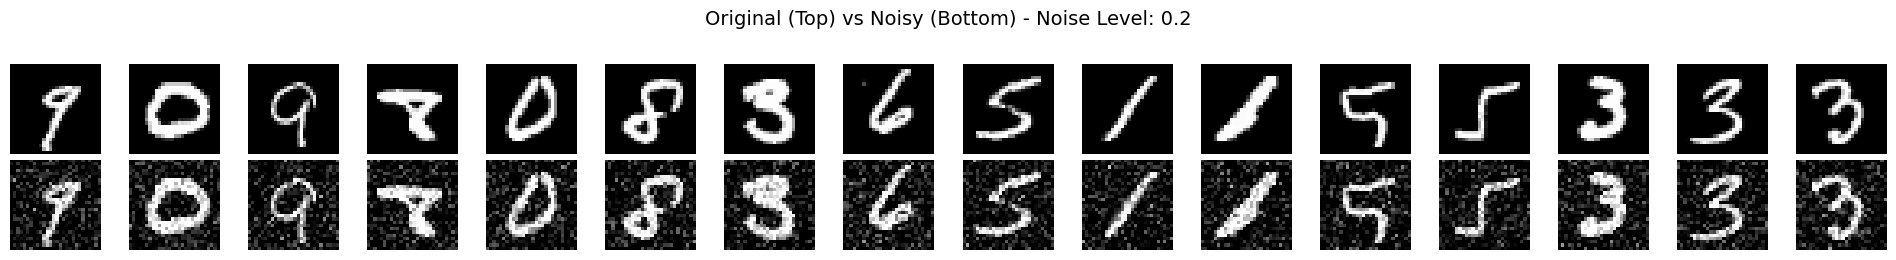

Denoising using Langevin sampling (noise_level=0.2)...
Displaying comparison: Original, Noisy, and Denoised (noise_level=0.2)...


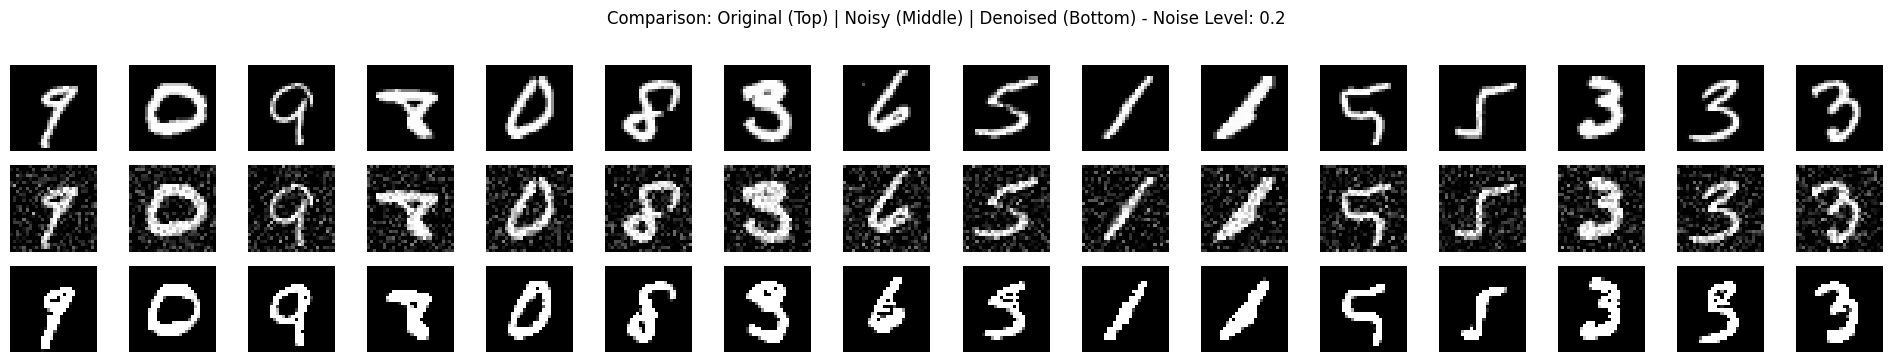


Quantitative Results for noise_level=0.2:
  MSE (Original vs Noisy): 0.021018
  MSE (Original vs Denoised): 0.032334
  Improvement: -53.84% reduction in MSE

----------------------------------------------------------------------

Processing Noise Level: 0.4

Displaying original and noisy images (noise_level=0.4)...


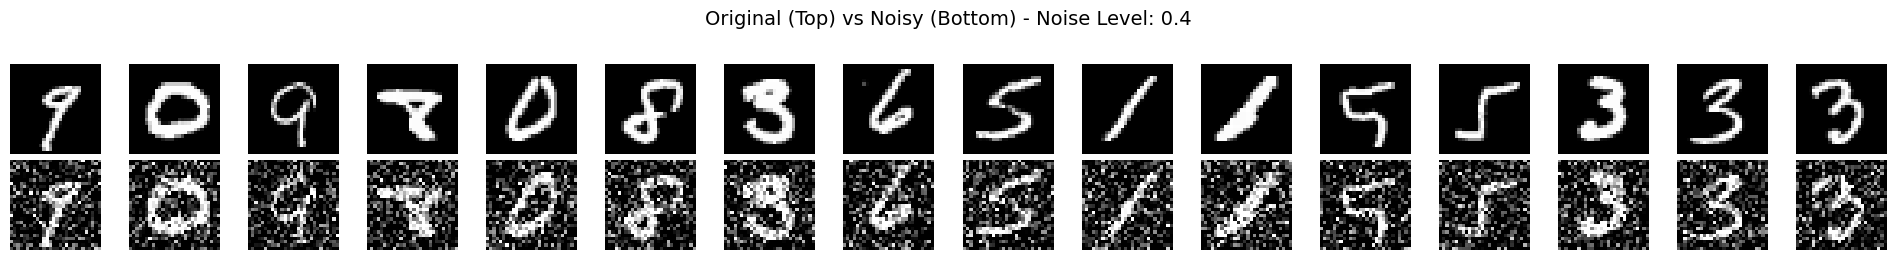

Denoising using Langevin sampling (noise_level=0.4)...
Displaying comparison: Original, Noisy, and Denoised (noise_level=0.4)...


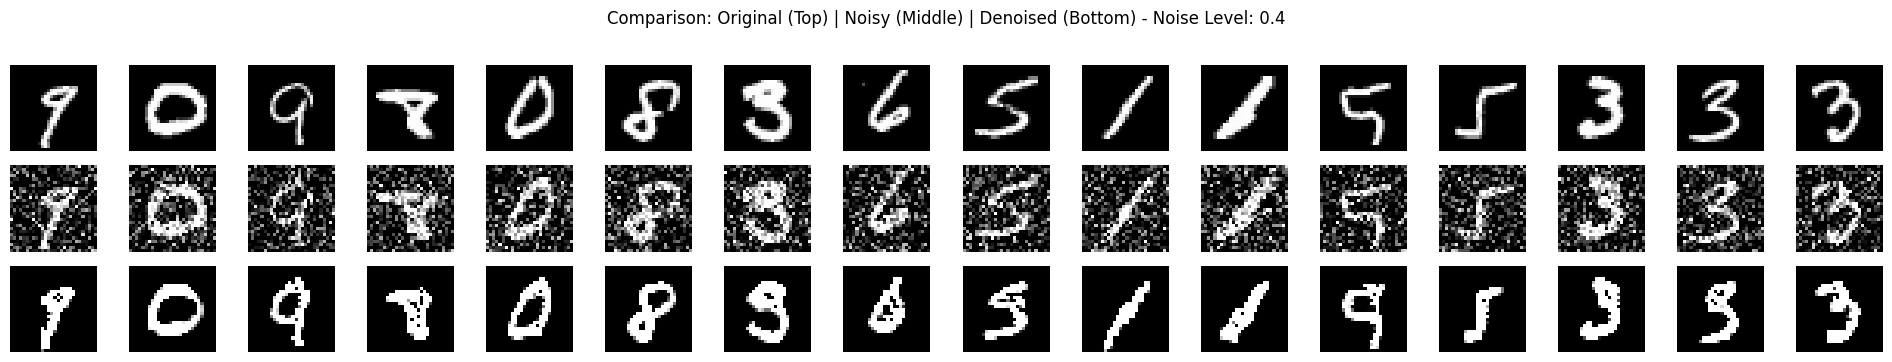


Quantitative Results for noise_level=0.4:
  MSE (Original vs Noisy): 0.078736
  MSE (Original vs Denoised): 0.041252
  Improvement: 47.61% reduction in MSE

----------------------------------------------------------------------

Processing Noise Level: 0.6

Displaying original and noisy images (noise_level=0.6)...


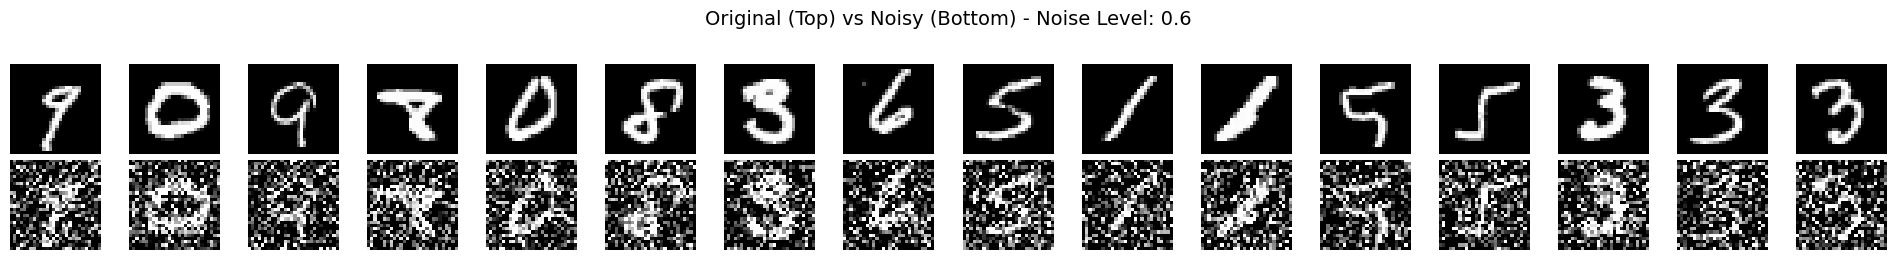

Denoising using Langevin sampling (noise_level=0.6)...
Displaying comparison: Original, Noisy, and Denoised (noise_level=0.6)...


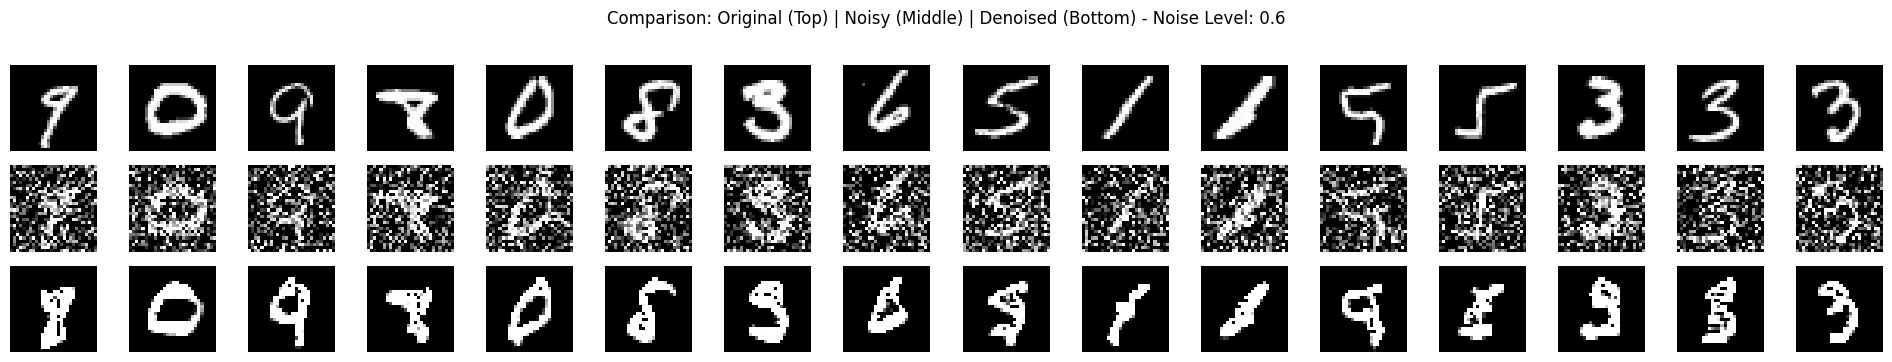


Quantitative Results for noise_level=0.6:
  MSE (Original vs Noisy): 0.153299
  MSE (Original vs Denoised): 0.055091
  Improvement: 64.06% reduction in MSE

----------------------------------------------------------------------


In [26]:
# Process each noise level
for noise_level in noise_levels:
    print(f"\n{'='*70}")
    print(f"Processing Noise Level: {noise_level}")
    print(f"{'='*70}\n")

    # Step 1: Add Gaussian noise
    noisy_images = add_gaussian_noise(test_images_batch, noise_level)

    # Step 2: Display noisy images alongside original images
    print(f"Displaying original and noisy images (noise_level={noise_level})...")
    fig, axes = plt.subplots(2, num_test_images, figsize=(num_test_images*1.2, 2.5))

    for i in range(num_test_images):
        # Original images (top row)
        axes[0, i].imshow(test_images_batch[i].cpu().squeeze(), cmap='gray')
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_ylabel('Original', fontsize=12)

        # Noisy images (bottom row)
        axes[1, i].imshow(noisy_images[i].cpu().squeeze(), cmap='gray')
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_ylabel('Noisy', fontsize=12)

    plt.suptitle(f'Original (Top) vs Noisy (Bottom) - Noise Level: {noise_level}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # Step 3: Use Langevin sampling for denoising (noisy images as initial input)
    print(f"Denoising using Langevin sampling (noise_level={noise_level})...")
    with torch.no_grad():
        denoised_images = langevin_sampling(
            model,
            x_init=noisy_images,  # Use noisy images as starting point
            num_samples=num_test_images,
            num_steps=60,  # Sufficient number of sampling steps
            step_size=0.01,
            noise_scale=0.01,
            device=device
        )

    # Step 4: Display denoised images alongside original and noisy images
    print(f"Displaying comparison: Original, Noisy, and Denoised (noise_level={noise_level})...")
    fig, axes = plt.subplots(3, num_test_images, figsize=(num_test_images*1.2, 3.5))

    for i in range(num_test_images):
        # Original images (top row)
        axes[0, i].imshow(test_images_batch[i].cpu().squeeze(), cmap='gray')
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_ylabel('Original', fontsize=12)

        # Noisy images (middle row)
        axes[1, i].imshow(noisy_images[i].cpu().squeeze(), cmap='gray')
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_ylabel('Noisy', fontsize=12)

        # Denoised images (bottom row)
        axes[2, i].imshow(denoised_images[i].cpu().squeeze(), cmap='gray')
        axes[2, i].axis('off')
        if i == 0:
            axes[2, i].set_ylabel('Denoised', fontsize=12)

    plt.suptitle(f'Comparison: Original (Top) | Noisy (Middle) | Denoised (Bottom) - Noise Level: {noise_level}',
                 fontsize=12, y=1.02)
    plt.tight_layout()
    plt.show()

    # Compute MSE for quantitative evaluation
    mse_noisy = ((test_images_batch - noisy_images) ** 2).mean().item()
    mse_denoised = ((test_images_batch - denoised_images) ** 2).mean().item()

    print(f"\nQuantitative Results for noise_level={noise_level}:")
    print(f"  MSE (Original vs Noisy): {mse_noisy:.6f}")
    print(f"  MSE (Original vs Denoised): {mse_denoised:.6f}")
    print(f"  Improvement: {((mse_noisy - mse_denoised) / mse_noisy * 100):.2f}% reduction in MSE")

    print("\n" + "-"*70)


### Analysis and Report Requirements

**In the report:**

1. **Denoising Effectiveness Analysis:**
   - For each noise level (0.2, 0.4, 0.6), explain to what extent the denoised image has approached the original image.
   - Compare the visual quality: Are the denoised images clearer than the noisy ones?
   - Are the digit structures preserved and recognizable after denoising?

2. **Model Performance Analysis:**
   - Among the three noise values (0.2, 0.4, 0.6), identify where the model was successful in denoising.
   - Identify where the model failed or struggled.
   - Explain why the model might perform better or worse at different noise levels.
   - Consider factors such as:
     - How much information is lost at high noise levels
     - Whether the Langevin sampling parameters are optimal for denoising
     - The model's ability to recover structure from heavily corrupted images

3. **Observations:**
   - Note any patterns you observe across different noise levels
   - Compare the denoising results with the image generation results from Subsection 3
